### CARTPOLE

In [5]:
import os
os.getcwd()

os.chdir("/Users/richardfisher/Desktop/projects/RainbowDQNAgent")


In [ ]:
ckpt_path = "models/CartPole/DDQN/model_solved_1766145727.pth"
checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=False)
rewards = checkpoint["reward_history"]

ckpt_path = "models/CartPole/Rainbow/model_solved_1766146372.pth"
checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=False)
rewards = checkpoint["reward_history"]

In [10]:
ckpt_path = "models/CartPole/Rainbow/model_solved_1766146372.pth"
checkpoint = torch.load(ckpt_path, map_location="cpu", weights_only=False)
rewards = checkpoint["reward_history"]

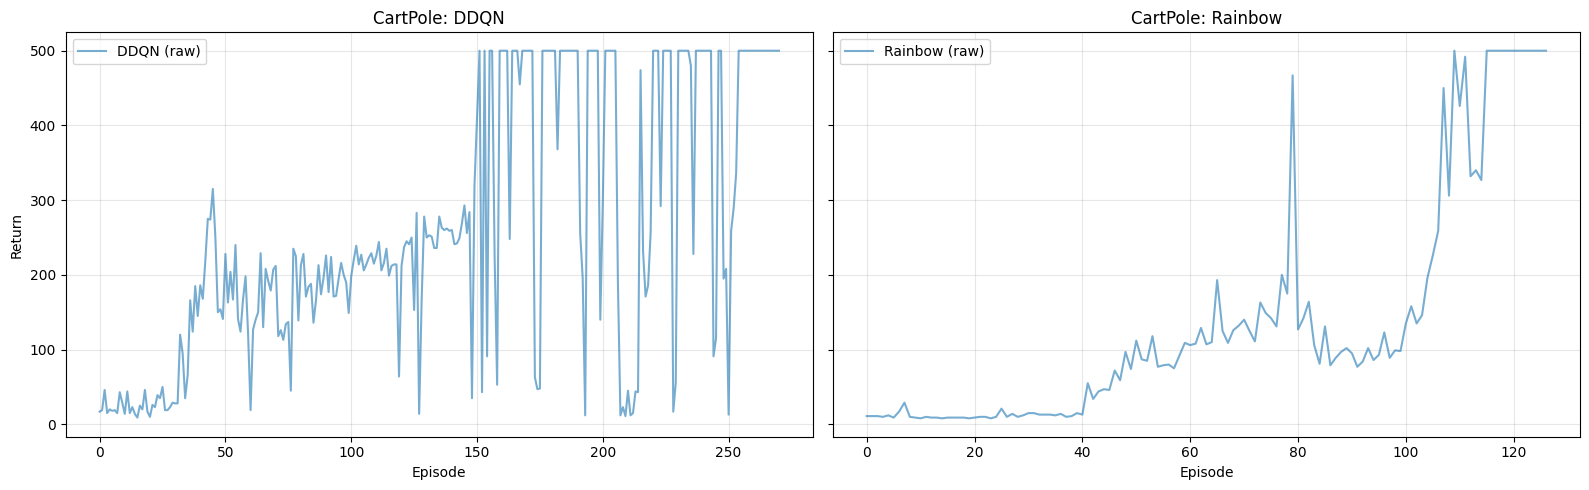

In [40]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Setup
# ---------------------------
PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

# ---------------------------
# Load rewards
# ---------------------------
ddqn_rewards = torch.load(
    "models/CartPole/DDQN/two.pth",
    map_location="cpu",
    weights_only=False
)["reward_history"]

rainbow_rewards = torch.load(
    "models/CartPole/Rainbow/two.pth",
    map_location="cpu",
    weights_only=False
)["reward_history"]

# ---------------------------
# Plot (horizontal layout)
# ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# ---- DDQN ----
axes[0].plot(ddqn_rewards, alpha=0.6, label="DDQN (raw)")
axes[0].set_title("CartPole: DDQN")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].grid(alpha=0.3)
axes[0].legend()

# ---- Rainbow ----
axes[1].plot(rainbow_rewards, alpha=0.6, label="Rainbow (raw)")
axes[1].set_title("CartPole: Rainbow")
axes[1].set_xlabel("Episode")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


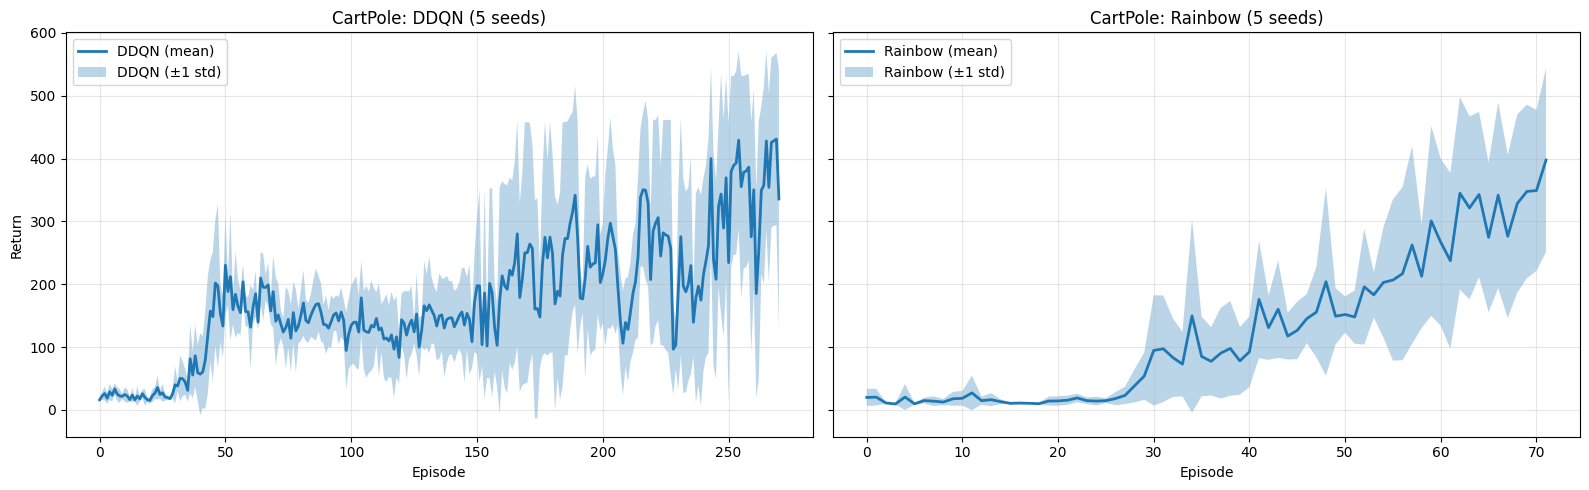

In [45]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Setup
# ---------------------------
PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

DDQN_DIR = "models/CartPole/DDQN"
RAINBOW_DIR = "models/CartPole/Rainbow"
seed_files = ["one.pth", "two.pth", "three.pth", "four.pth", "five.pth"]

# ---------------------------
# Helper to load runs
# ---------------------------
def load_runs(base_dir, files):
    runs = []
    for f in files:
        ckpt = torch.load(
            os.path.join(base_dir, f),
            map_location="cpu",
            weights_only=False
        )
        runs.append(np.array(ckpt["reward_history"]))
    return runs

# ---------------------------
# Load data
# ---------------------------
ddqn_runs = load_runs(DDQN_DIR, seed_files)
rainbow_runs = load_runs(RAINBOW_DIR, seed_files)

# ---------------------------
# Align lengths (per algorithm)
# ---------------------------
min_len_ddqn = min(len(r) for r in ddqn_runs)
min_len_rainbow = min(len(r) for r in rainbow_runs)

ddqn_runs = np.array([r[:min_len_ddqn] for r in ddqn_runs])
rainbow_runs = np.array([r[:min_len_rainbow] for r in rainbow_runs])

# ---------------------------
# Statistics
# ---------------------------
ddqn_mean = ddqn_runs.mean(axis=0)
ddqn_std = ddqn_runs.std(axis=0)
ddqn_eps = np.arange(min_len_ddqn)

rainbow_mean = rainbow_runs.mean(axis=0)
rainbow_std = rainbow_runs.std(axis=0)
rainbow_eps = np.arange(min_len_rainbow)

# ---------------------------
# Plot (horizontal layout)
# ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# ---- DDQN (left) ----
axes[0].plot(ddqn_eps, ddqn_mean, linewidth=2, label="DDQN (mean)")
axes[0].fill_between(
    ddqn_eps,
    ddqn_mean - ddqn_std,
    ddqn_mean + ddqn_std,
    alpha=0.3,
    label="DDQN (±1 std)"
)
axes[0].set_title("CartPole: DDQN (5 seeds)")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].grid(alpha=0.3)
axes[0].legend()

# ---- Rainbow (right) ----
axes[1].plot(rainbow_eps, rainbow_mean, linewidth=2, label="Rainbow (mean)")
axes[1].fill_between(
    rainbow_eps,
    rainbow_mean - rainbow_std,
    rainbow_mean + rainbow_std,
    alpha=0.3,
    label="Rainbow (±1 std)"
)
axes[1].set_title("CartPole: Rainbow (5 seeds)")
axes[1].set_xlabel("Episode")
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


### Lunar

In [30]:
import os
os.getcwd()

os.chdir("/Users/richardfisher/Desktop/projects/RainbowDQNAgent")

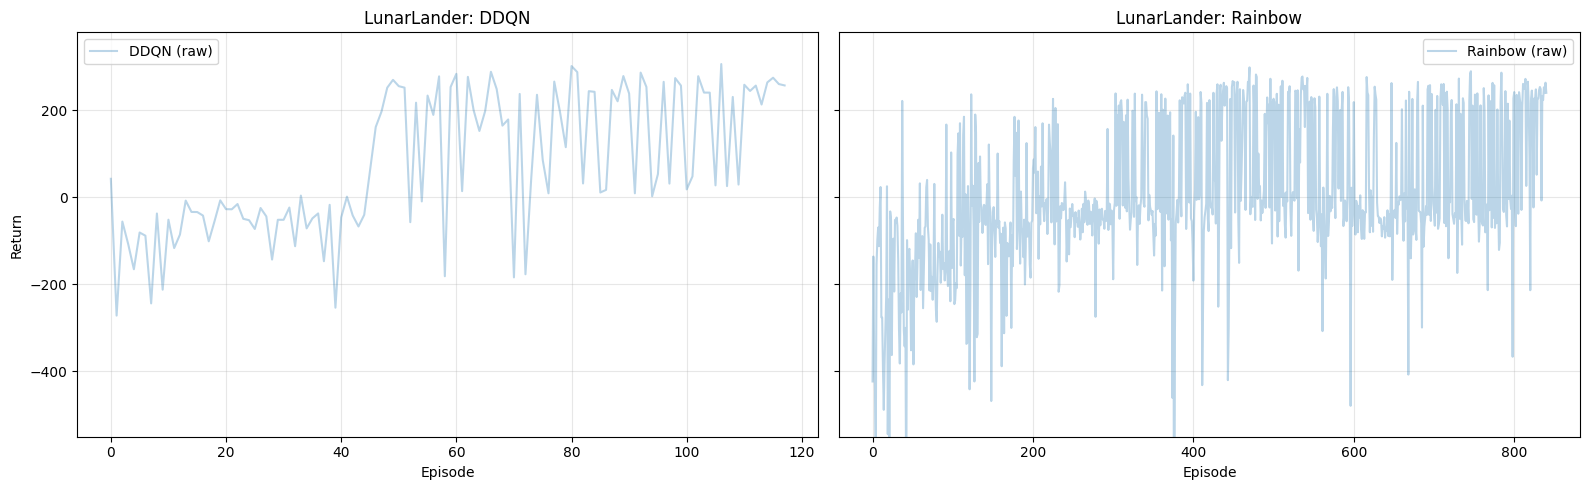

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Setup
# ---------------------------
PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

# ---------------------------
# Load rewards
# ---------------------------
ddqn_rewards = torch.load(
    "models/Lunarlander/DDQN/model_solved_1766163288.pth",
    map_location="cpu",
    weights_only=False
)["reward_history"]

rainbow_rewards = torch.load(
    "models/Lunarlander/Rainbow/final.pth",
    map_location="cpu",
    weights_only=False
)["reward_history"]

# ---------------------------
# Moving average
# ---------------------------
def moving_average(x, window=10):
    x = np.asarray(x)
    if len(x) < window:
        return x
    return np.convolve(x, np.ones(window) / window, mode="valid")

# ---------------------------
# Plot (horizontal layout)
# ---------------------------
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

# ---- DDQN ----
axes[0].plot(ddqn_rewards, alpha=0.3, label="DDQN (raw)")
# axes[0].plot(
#     moving_average(ddqn_rewards, 10),
#     linewidth=2,
#     label="DDQN (smoothed)"
# )
axes[0].set_title("LunarLander: DDQN")
axes[0].set_xlabel("Episode")
axes[0].set_ylabel("Return")
axes[0].grid(alpha=0.3)
axes[0].legend()

# ---- Rainbow ----
axes[1].plot(rainbow_rewards, alpha=0.3, label="Rainbow (raw)")
# axes[1].plot(
#     moving_average(rainbow_rewards, 10),
#     linewidth=2,
#     label="Rainbow (smoothed)"
# )
axes[1].set_title("LunarLander: Rainbow")
axes[1].set_xlabel("Episode")
axes[0].set_ylim(bottom=-550)
axes[1].set_ylim(bottom=-550)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()

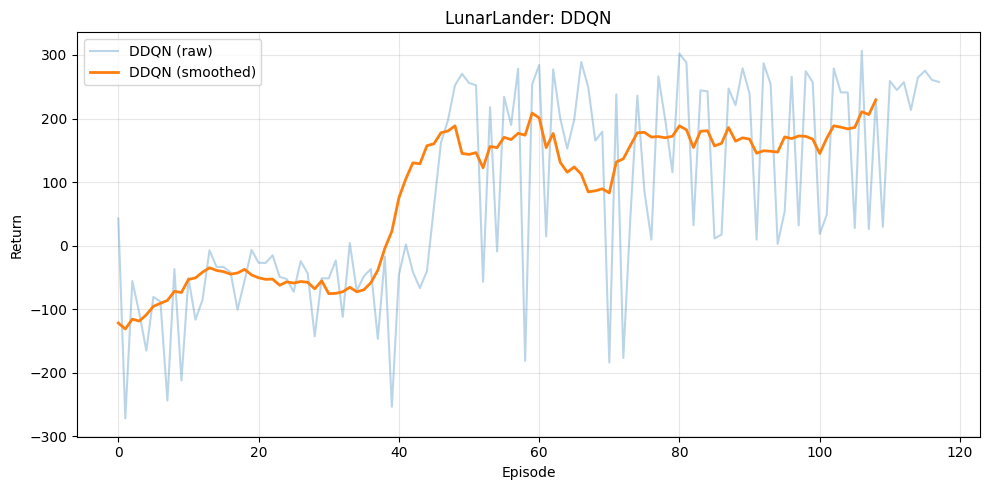

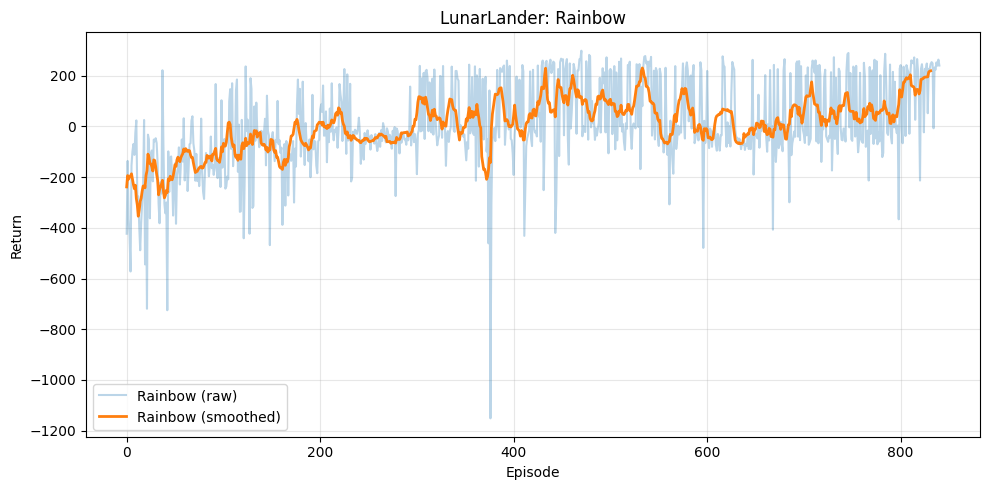

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# ---------------------------
# Setup
# ---------------------------
PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

# ---------------------------
# Load rewards
# ---------------------------
ddqn_rewards = torch.load(
    "models/Lunarlander/DDQN/model_solved_1766163288.pth",
    map_location="cpu",
    weights_only=False
)["reward_history"]

rainbow_rewards = torch.load(
    "models/Lunarlander/Rainbow/final.pth",
    map_location="cpu",
    weights_only=False
)["reward_history"]

# ---------------------------
# Moving average
# ---------------------------
def moving_average(x, window=10):
    x = np.asarray(x)
    if len(x) < window:
        return x
    return np.convolve(x, np.ones(window) / window, mode="valid")

# ---------------------------
# Plot DDQN
# ---------------------------
plt.figure(figsize=(10, 5))
plt.plot(ddqn_rewards, alpha=0.3, label="DDQN (raw)")
plt.plot(moving_average(ddqn_rewards, 10), linewidth=2, label="DDQN (smoothed)")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.title("LunarLander: DDQN")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# ---------------------------
# Plot Rainbow
# ---------------------------
plt.figure(figsize=(10, 5))
plt.plot(rainbow_rewards, alpha=0.3, label="Rainbow (raw)")
plt.plot(moving_average(rainbow_rewards, 10), linewidth=2, label="Rainbow (smoothed)")
plt.xlabel("Episode")
plt.ylabel("Return")
plt.title("LunarLander: Rainbow")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

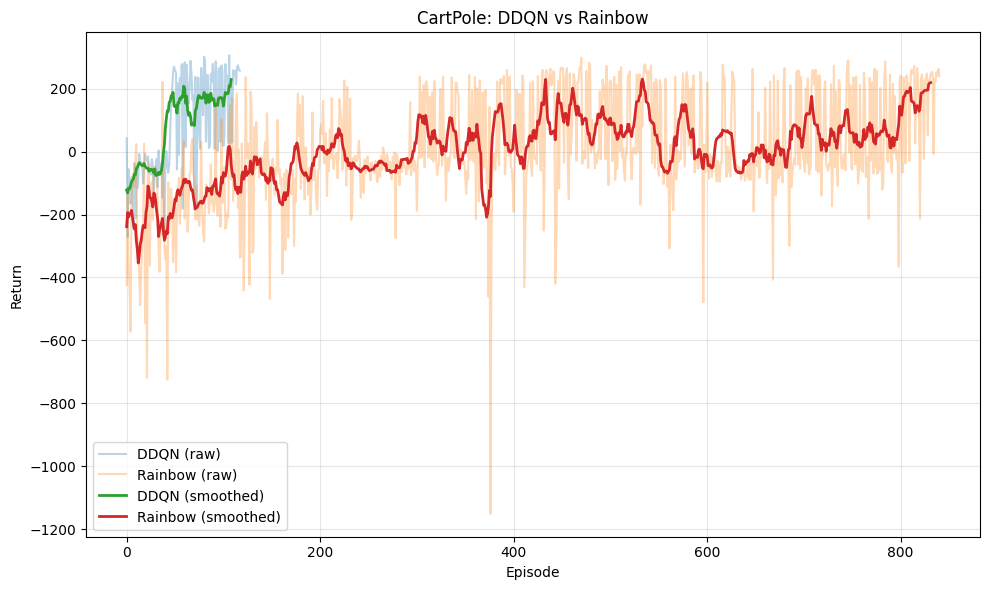

In [ ]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

# Ensure we're in project root (safe for Jupyter)
PROJECT_ROOT = "/Users/richardfisher/Desktop/projects/RainbowDQNAgent"
os.chdir(PROJECT_ROOT)

# Load DDQN rewards
ddqn_ckpt = "models/Lunarlander/DDQN/model_solved_1766163288.pth"
ddqn_rewards = torch.load(
    ddqn_ckpt, map_location="cpu", weights_only=False
)["reward_history"]

# Load Rainbow rewards
rainbow_ckpt = "models/Lunarlander/Rainbow/final.pth"
rainbow_rewards = torch.load(
    rainbow_ckpt, map_location="cpu", weights_only=False
)["reward_history"]



# Moving average smoothing
def moving_average(x, window=10):
    x = np.asarray(x)
    if len(x) < window:
        return x
    return np.convolve(x, np.ones(window) / window, mode="valid")

# Plot
plt.figure(figsize=(10, 6))

plt.plot(ddqn_rewards, alpha=0.3, label="DDQN (raw)")
plt.plot(rainbow_rewards, alpha=0.3, label="Rainbow (raw)")

plt.plot(
    moving_average(ddqn_rewards, 10),
    linewidth=2,
    label="DDQN (smoothed)"
)
plt.plot(
    moving_average(rainbow_rewards, 10),
    linewidth=2,
    label="Rainbow (smoothed)"
)

plt.xlabel("Episode")
plt.ylabel("Return")
plt.title("CartPole: DDQN vs Rainbow")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()